In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("datatraining.txt")

print("First 5 rows:")
print(df.head())

print("\nDataset shape:")
print(df.shape)

print("\nColumn names:")
print(df.columns)

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nSummary statistics:")
print(df.describe())

print("\nOccupancy distribution:")
print(df["Occupancy"].value_counts())

features = ["Temperature", "Humidity", "Light", "CO2"]

for feature in features:
    plt.figure(figsize=(10,4))
    plt.plot(df[feature])
    plt.title(f"{feature} Over Time")
    plt.xlabel("Time (s)")
    plt.ylabel(feature)
    plt.grid(True)
    plt.show()

for feature in features:
    plt.figure(figsize=(6,4))

    plt.hist(
        df[df["Occupancy"] == 0][feature],
        bins=30,
        alpha=0.6,
        label="Unoccupied"
    )

    plt.hist(
        df[df["Occupancy"] == 1][feature],
        bins=30,
        alpha=0.6,
        label="Occupied"
    )

    plt.title(f"{feature} Distribution")
    plt.xlabel(feature)
    plt.ylabel("Count")
    plt.legend()
    plt.show()

# Classical Comms Implementation

In [7]:
import numpy as np

def repetition_encode(bits, n=3):
    bits = np.array(bits, dtype=int)
    return np.repeat(bits, n)


def repetition_decode(bits, n=3):
    bits = np.array(bits, dtype=int)

    decoded = []

    for i in range(0, len(bits), n):
        block = bits[i:i+n]

        if len(block) < n:
            break

        decoded.append(int(np.sum(block) >= (n//2 + 1)))

    return np.array(decoded)

def hamming74_encode(bits):
    bits = np.array(bits, dtype=int)

    pad = (-len(bits)) % 4
    if pad:
        bits = np.concatenate([bits, np.zeros(pad, dtype=int)])

    encoded = []

    for i in range(0, len(bits), 4):

        d1, d2, d3, d4 = bits[i:i+4]

        p1 = d1 ^ d2 ^ d4
        p2 = d1 ^ d3 ^ d4
        p3 = d2 ^ d3 ^ d4

        codeword = [
            p1,
            p2,
            d1,
            p3,
            d2,
            d3,
            d4
        ]

        encoded.extend(codeword)

    return np.array(encoded)


def hamming74_decode(bits):

    bits = np.array(bits, dtype=int)

    decoded = []

    for i in range(0, len(bits), 7):

        if i + 7 > len(bits):
            break

        c = bits[i:i+7].copy()

        s1 = c[0] ^ c[2] ^ c[4] ^ c[6]
        s2 = c[1] ^ c[2] ^ c[5] ^ c[6]
        s3 = c[3] ^ c[4] ^ c[5] ^ c[6]

        error = s1 + 2*s2 + 4*s3

        if error != 0:
            c[error-1] ^= 1

        decoded.extend([
            c[2],
            c[4],
            c[5],
            c[6]
        ])

    return np.array(decoded)

def bpsk_modulate(bits):
    bits = np.array(bits)
    return 2*bits - 1


def bpsk_demodulate(symbols):
    return (symbols >= 0).astype(int)

def qpsk_modulate(bits):

    bits = np.array(bits)

    if len(bits) % 2:
        bits = np.append(bits, 0)

    symbols = []

    for i in range(0, len(bits), 2):

        b1 = bits[i]
        b2 = bits[i+1]

        if (b1, b2) == (0,0):
            s = 1 + 1j

        elif (b1,b2)==(0,1):
            s = -1 + 1j

        elif (b1,b2)==(1,1):
            s = -1 -1j

        else:
            s = 1 -1j

        symbols.append(s/np.sqrt(2))

    return np.array(symbols)


def qpsk_demodulate(symbols):

    bits = []

    for s in symbols:

        real = np.real(s)
        imag = np.imag(s)

        if real >= 0 and imag >=0:
            bits.extend([0,0])

        elif real <0 and imag>=0:
            bits.extend([0,1])

        elif real <0 and imag<0:
            bits.extend([1,1])

        else:
            bits.extend([1,0])

    return np.array(bits)

def awgn_channel(signal, snr_db):

    signal = np.array(signal)

    snr_linear = 10**(snr_db/10)

    power = np.mean(np.abs(signal)**2)

    noise_power = power/snr_linear

    if np.iscomplexobj(signal):

        noise = (
            np.random.normal(
                0,
                np.sqrt(noise_power/2),
                signal.shape
            )
            +
            1j*np.random.normal(
                0,
                np.sqrt(noise_power/2),
                signal.shape
            )
        )

    else:

        noise = np.random.normal(
            0,
            np.sqrt(noise_power),
            signal.shape
        )

    return signal + noise

def bit_error_rate(original, recovered):

    original = np.array(original)
    recovered = np.array(recovered)

    n = min(len(original), len(recovered))

    return np.mean(original[:n] != recovered[:n])

    import numpy as np

def awgn_channel(signal, snr_db):

    signal = np.asarray(signal)

    signal_power = np.mean(np.abs(signal) ** 2)

    snr_linear = 10 ** (snr_db / 10)

    noise_power = signal_power / snr_linear

    if np.iscomplexobj(signal):
        noise = (
            np.random.normal(0, np.sqrt(noise_power / 2), signal.shape)
            + 1j * np.random.normal(0, np.sqrt(noise_power / 2), signal.shape)
        )
    else:
        noise = np.random.normal(
            0,
            np.sqrt(noise_power),
            signal.shape
        )

    return signal + noise

In [10]:
import numpy as np
import pandas as pd

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

def bit_error_rate(original, recovered):

    original = np.array(original)
    recovered = np.array(recovered)

    n = min(len(original), len(recovered))

    return np.mean(original[:n] != recovered[:n])

train = pd.read_csv("datatraining.txt")
test = pd.read_csv("datatest.txt")

features = ["Temperature", "Humidity", "Light", "CO2"]

classifier = LogisticRegression(max_iter=1000)

classifier.fit(
    train[features],
    train["Occupancy"]
)

mins = train[features].min()
maxs = train[features].max()


def quantize(value, minimum, maximum, bits=16):

    normalized = (value - minimum) / (maximum - minimum)

    normalized = np.clip(normalized, 0, 1)

    integer = int(round(normalized * (2**bits - 1)))

    return np.array(
        list(np.binary_repr(integer, width=bits)),
        dtype=int
    )


def dequantize(bits, minimum, maximum):

    integer = int("".join(bits.astype(str)), 2)

    normalized = integer / (2**16 - 1)

    return normalized * (maximum - minimum) + minimum

def row_to_bits(row):

    bitstream = []

    for feature in features:

        b = quantize(
            row[feature],
            mins[feature],
            maxs[feature]
        )

        bitstream.extend(b)

    return np.array(bitstream)


def bits_to_row(bits):

    values = []

    index = 0

    for feature in features:

        value = dequantize(
            bits[index:index+16],
            mins[feature],
            maxs[feature]
        )

        values.append(value)

        index += 16

    return values


def transmit(bitstream, modulation, snr):

    encoded = hamming74_encode(bitstream)

    if modulation == "BPSK":

        tx = bpsk_modulate(encoded)

        rx = awgn_channel(tx, snr)

        received = bpsk_demodulate(rx)

    elif modulation == "QPSK":

        tx = qpsk_modulate(encoded)

        rx = awgn_channel(tx, snr)

        received = qpsk_demodulate(rx)

    else:

        raise ValueError("Unknown modulation")

    decoded = hamming74_decode(received)

    decoded = decoded[:len(bitstream)]

    ber = bit_error_rate(bitstream, decoded)

    return decoded, ber

snrs = np.arange(-10, 22, 2)

for modulation in ["BPSK", "QPSK"]:

    print("\n", modulation)

    for snr in snrs:

        bers = []

        reconstructed = []

        for _, row in test.iterrows():

            bits = row_to_bits(row)

            recovered, ber = transmit(
                bits,
                modulation,
                snr
            )

            bers.append(ber)

            reconstructed.append(
                bits_to_row(recovered)
            )

        reconstructed = pd.DataFrame(
            reconstructed,
            columns=features
        )

        prediction = classifier.predict(reconstructed)

        accuracy = accuracy_score(
            test["Occupancy"],
            prediction
        )

        print(
            f"SNR={snr:>3} dB | "
            f"BER={np.mean(bers):.4f} | "
            f"Accuracy={accuracy:.4f}"
        )



 BPSK
SNR=-10 dB | BER=0.4002 | Accuracy=0.4728
SNR= -8 dB | BER=0.3686 | Accuracy=0.5032
SNR= -6 dB | BER=0.3297 | Accuracy=0.5587
SNR= -4 dB | BER=0.2795 | Accuracy=0.6154
SNR= -2 dB | BER=0.2132 | Accuracy=0.6837
SNR=  0 dB | BER=0.1413 | Accuracy=0.7647
SNR=  2 dB | BER=0.0713 | Accuracy=0.8841
SNR=  4 dB | BER=0.0243 | Accuracy=0.9392
SNR=  6 dB | BER=0.0041 | Accuracy=0.9722
SNR=  8 dB | BER=0.0004 | Accuracy=0.9782
SNR= 10 dB | BER=0.0000 | Accuracy=0.9786
SNR= 12 dB | BER=0.0000 | Accuracy=0.9786
SNR= 14 dB | BER=0.0000 | Accuracy=0.9786
SNR= 16 dB | BER=0.0000 | Accuracy=0.9786
SNR= 18 dB | BER=0.0000 | Accuracy=0.9786
SNR= 20 dB | BER=0.0000 | Accuracy=0.9786

 QPSK
SNR=-10 dB | BER=0.4016 | Accuracy=0.4724
SNR= -8 dB | BER=0.3692 | Accuracy=0.5114
SNR= -6 dB | BER=0.3292 | Accuracy=0.5351
SNR= -4 dB | BER=0.2788 | Accuracy=0.5955
SNR= -2 dB | BER=0.2147 | Accuracy=0.6720
SNR=  0 dB | BER=0.1402 | Accuracy=0.7756
SNR=  2 dB | BER=0.0706 | Accuracy=0.8773
SNR=  4 dB | BER=0.0


Running BPSK
SNR=-10 dB | BER=0.4023 | ACC=0.4698
SNR= -8 dB | BER=0.3715 | ACC=0.4934
SNR= -6 dB | BER=0.3318 | ACC=0.5400
SNR= -4 dB | BER=0.2802 | ACC=0.6011
SNR= -2 dB | BER=0.2140 | ACC=0.6694
SNR=  0 dB | BER=0.1403 | ACC=0.7734
SNR=  2 dB | BER=0.0715 | ACC=0.8856
SNR=  4 dB | BER=0.0242 | ACC=0.9366
SNR=  6 dB | BER=0.0044 | ACC=0.9730
SNR=  8 dB | BER=0.0003 | ACC=0.9779
SNR= 10 dB | BER=0.0000 | ACC=0.9786
SNR= 12 dB | BER=0.0000 | ACC=0.9786
SNR= 14 dB | BER=0.0000 | ACC=0.9786
SNR= 16 dB | BER=0.0000 | ACC=0.9786
SNR= 18 dB | BER=0.0000 | ACC=0.9786
SNR= 20 dB | BER=0.0000 | ACC=0.9786

Running QPSK
SNR=-10 dB | BER=0.3984 | ACC=0.4653
SNR= -8 dB | BER=0.3717 | ACC=0.4946
SNR= -6 dB | BER=0.3284 | ACC=0.5328
SNR= -4 dB | BER=0.2814 | ACC=0.6045
SNR= -2 dB | BER=0.2178 | ACC=0.6687
SNR=  0 dB | BER=0.1418 | ACC=0.7707
SNR=  2 dB | BER=0.0715 | ACC=0.8784
SNR=  4 dB | BER=0.0244 | ACC=0.9388
SNR=  6 dB | BER=0.0046 | ACC=0.9689
SNR=  8 dB | BER=0.0004 | ACC=0.9790
SNR= 10 dB

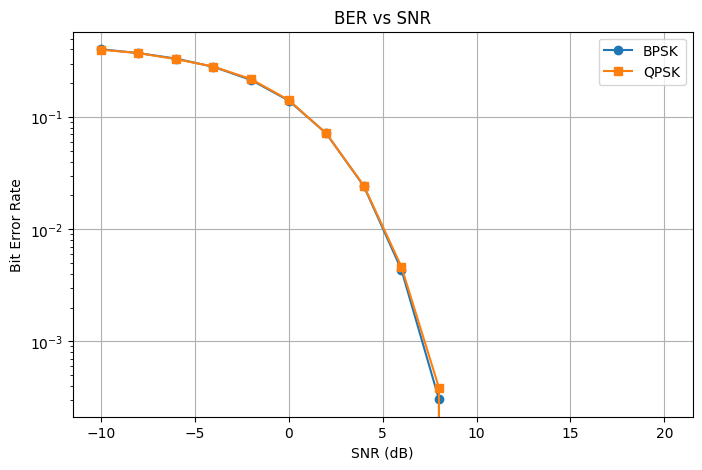

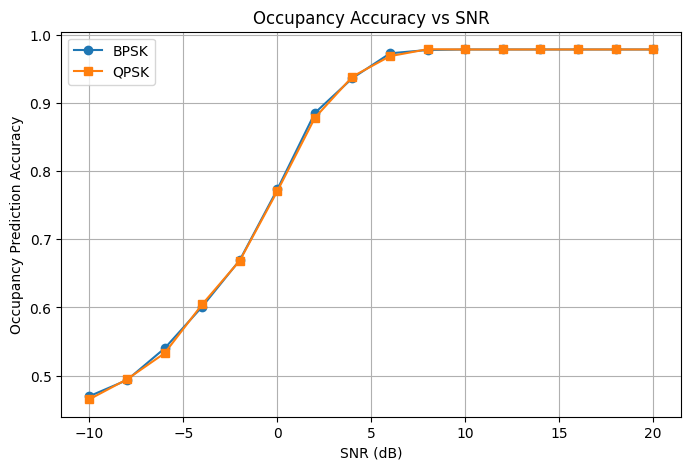

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score


train = pd.read_csv("datatraining.txt")
test = pd.read_csv("datatest.txt")

features = ["Temperature", "Humidity", "Light", "CO2"]

classifier = LogisticRegression(max_iter=1000)
classifier.fit(train[features], train["Occupancy"])

mins = train[features].min()
maxs = train[features].max()

def quantize(value, minimum, maximum, bits=16):

    value = (value-minimum)/(maximum-minimum)
    value = np.clip(value,0,1)

    integer = int(round(value*(2**bits-1)))

    return np.array(
        list(np.binary_repr(integer,width=bits)),
        dtype=int
    )

def dequantize(bits, minimum, maximum):

    integer = int("".join(bits.astype(str)),2)

    value = integer/(2**16-1)

    return value*(maximum-minimum)+minimum

def row_to_bits(row):

    bits=[]

    for f in features:

        bits.extend(
            quantize(
                row[f],
                mins[f],
                maxs[f]
            )
        )

    return np.array(bits)

def bits_to_row(bits):

    row=[]

    start=0

    for f in features:

        row.append(

            dequantize(

                bits[start:start+16],

                mins[f],

                maxs[f]

            )

        )

        start+=16

    return row

def communicate(bitstream, modulation="BPSK", snr_db=10, coding="hamming"):

    bitstream = np.array(bitstream, dtype=int)

    if coding == "hamming":
        encoded = hamming74_encode(bitstream)

    elif coding == "conv":
        encoded = conv_encode(bitstream)

    elif coding == "repetition":
        encoded = repetition_encode(bitstream, n=3)

    else:
        raise ValueError(
            "coding must be 'hamming', 'conv', or 'repetition'"
        )

    if modulation == "BPSK":
        transmitted = bpsk_modulate(encoded)
        received = awgn_channel(transmitted, snr_db)
        detected = bpsk_demodulate(received)

    elif modulation == "QPSK":
        transmitted = qpsk_modulate(encoded)
        received = awgn_channel(transmitted, snr_db)
        detected = qpsk_demodulate(received)

    elif modulation == "BFSK":
        transmitted = bfsk_modulate(encoded)
        received = awgn_channel(transmitted, snr_db)
        detected = bfsk_demodulate(received)

    else:
        raise ValueError(
            "modulation must be 'BPSK', 'QPSK', or 'BFSK'"
        )

    if coding == "hamming":
        decoded = hamming74_decode(detected)

    elif coding == "conv":
        decoded = viterbi_decode(
            detected,
            num_info_bits=len(bitstream)
        )

    elif coding == "repetition":
        decoded = repetition_decode(detected, n=3)

    decoded = decoded[:len(bitstream)]


    ber = bit_error_rate(bitstream, decoded)

    return decoded, ber

snrs=np.arange(-10,21,2)

results={}

for modulation in ["BPSK","QPSK"]:

    ber_curve=[]
    acc_curve=[]

    print("\nRunning",modulation)

    for snr in snrs:

        ber_list=[]
        reconstructed=[]

        for _,row in test.iterrows():

            bits=row_to_bits(row)

            recovered,ber=communicate(
                bits,
                modulation,
                snr
            )

            reconstructed.append(
                bits_to_row(recovered)
            )

            ber_list.append(ber)

        reconstructed=pd.DataFrame(
            reconstructed,
            columns=features
        )

        prediction=classifier.predict(reconstructed)

        accuracy=accuracy_score(
            test["Occupancy"],
            prediction
        )

        ber_curve.append(np.mean(ber_list))
        acc_curve.append(accuracy)

        print(
            f"SNR={snr:>3} dB | "
            f"BER={np.mean(ber_list):.4f} | "
            f"ACC={accuracy:.4f}"
        )

    results[modulation]={
        "BER":ber_curve,
        "ACC":acc_curve
    }

plt.figure(figsize=(8,5))

plt.semilogy(
    snrs,
    results["BPSK"]["BER"],
    marker='o',
    label="BPSK"
)

plt.semilogy(
    snrs,
    results["QPSK"]["BER"],
    marker='s',
    label="QPSK"
)

plt.xlabel("SNR (dB)")
plt.ylabel("Bit Error Rate")
plt.title("BER vs SNR")
plt.grid(True)
plt.legend()

plt.savefig("ber_vs_snr.png",dpi=300)

plt.figure(figsize=(8,5))

plt.plot(
    snrs,
    results["BPSK"]["ACC"],
    marker='o',
    label="BPSK"
)

plt.plot(
    snrs,
    results["QPSK"]["ACC"],
    marker='s',
    label="QPSK"
)

plt.xlabel("SNR (dB)")
plt.ylabel("Occupancy Prediction Accuracy")
plt.title("Occupancy Accuracy vs SNR")
plt.grid(True)
plt.legend()

plt.savefig(
    "accuracy_vs_snr.png",
    dpi=300
)

plt.show()

In [12]:
mins = train[features].min()
maxs = train[features].max()


def quantize(value, minimum, maximum, bits=16):

    normalized = (value - minimum) / (maximum - minimum)
    normalized = np.clip(normalized, 0, 1)

    integer = int(round(normalized * (2**bits - 1)))

    binary = np.binary_repr(integer, width=bits)

    return np.array(list(binary), dtype=int)


def dequantize(bit_array, minimum, maximum, bits=16):

    integer = int("".join(bit_array.astype(str)), 2)

    normalized = integer / (2**bits - 1)

    return normalized * (maximum - minimum) + minimum


def row_to_bits(row):

    bitstream = []

    for feature in features:
        bits = quantize(
            row[feature],
            mins[feature],
            maxs[feature]
        )

        bitstream.extend(bits)

    return np.array(bitstream)


def bits_to_row(bitstream):

    values = []

    for i, feature in enumerate(features):

        start = i * 16
        end = start + 16

        value = dequantize(
            bitstream[start:end],
            mins[feature],
            maxs[feature]
        )

        values.append(value)

    return values

In [13]:
import numpy as np

def repetition_encode(bits, n=3):
    bits = np.array(bits, dtype=int)
    return np.repeat(bits, n)


def repetition_decode(bits, n=3):
    bits = np.array(bits, dtype=int)

    decoded = []

    for i in range(0, len(bits), n):
        block = bits[i:i+n]

        if len(block) < n:
            break

        decoded.append(int(np.sum(block) >= (n // 2 + 1)))

    return np.array(decoded)

def hamming74_encode(bits):

    bits = np.array(bits, dtype=int)

    pad = (-len(bits)) % 4
    if pad:
        bits = np.concatenate([bits, np.zeros(pad, dtype=int)])

    encoded = []

    for i in range(0, len(bits), 4):

        d1, d2, d3, d4 = bits[i:i+4]

        p1 = d1 ^ d2 ^ d4
        p2 = d1 ^ d3 ^ d4
        p3 = d2 ^ d3 ^ d4

        encoded.extend([
            p1,
            p2,
            d1,
            p3,
            d2,
            d3,
            d4
        ])

    return np.array(encoded)


def hamming74_decode(bits):

    bits = np.array(bits, dtype=int)

    decoded = []

    for i in range(0, len(bits), 7):

        if i + 7 > len(bits):
            break

        c = bits[i:i+7].copy()

        s1 = c[0] ^ c[2] ^ c[4] ^ c[6]
        s2 = c[1] ^ c[2] ^ c[5] ^ c[6]
        s3 = c[3] ^ c[4] ^ c[5] ^ c[6]

        error = s1 + 2*s2 + 4*s3

        if error != 0:
            c[error-1] ^= 1

        decoded.extend([
            c[2],
            c[4],
            c[5],
            c[6]
        ])

    return np.array(decoded)

def bpsk_modulate(bits):
    bits = np.array(bits)
    return 2*bits - 1


def bpsk_demodulate(symbols):
    return (symbols >= 0).astype(int)

def qpsk_modulate(bits):

    bits = np.array(bits)

    if len(bits) % 2:
        bits = np.append(bits, 0)

    symbols = []

    for i in range(0, len(bits), 2):

        b1 = bits[i]
        b2 = bits[i+1]

        if (b1, b2) == (0,0):
            symbol = 1 + 1j

        elif (b1, b2) == (0,1):
            symbol = -1 + 1j

        elif (b1, b2) == (1,1):
            symbol = -1 - 1j

        else:
            symbol = 1 - 1j

        symbols.append(symbol / np.sqrt(2))

    return np.array(symbols)


def qpsk_demodulate(symbols):

    bits = []

    for s in symbols:

        if np.real(s) >= 0 and np.imag(s) >= 0:
            bits.extend([0,0])

        elif np.real(s) < 0 and np.imag(s) >= 0:
            bits.extend([0,1])

        elif np.real(s) < 0 and np.imag(s) < 0:
            bits.extend([1,1])

        else:
            bits.extend([1,0])

    return np.array(bits)

def awgn_channel(signal, snr_db):

    signal = np.asarray(signal)

    signal_power = np.mean(np.abs(signal)**2)

    snr_linear = 10**(snr_db/10)

    noise_power = signal_power / snr_linear

    if np.iscomplexobj(signal):

        noise = (
            np.random.normal(
                0,
                np.sqrt(noise_power/2),
                signal.shape
            )
            +
            1j*np.random.normal(
                0,
                np.sqrt(noise_power/2),
                signal.shape
            )
        )

    else:

        noise = np.random.normal(
            0,
            np.sqrt(noise_power),
            signal.shape
        )

    return signal + noise

def bit_error_rate(original, recovered):

    original = np.array(original)
    recovered = np.array(recovered)

    n = min(len(original), len(recovered))

    return np.mean(original[:n] != recovered[:n])

def qam16_modulate(bits):

    bits = np.array(bits, dtype=int)

    pad = (-len(bits)) % 4
    if pad:
        bits = np.concatenate([bits, np.zeros(pad, dtype=int)])

    gray_to_level = {(0, 0): -3, (0, 1): -1, (1, 1): 1, (1, 0): 3}

    symbols = []

    for i in range(0, len(bits), 4):

        b1, b2, b3, b4 = bits[i:i+4]

        I = gray_to_level[(b1, b2)]
        Q = gray_to_level[(b3, b4)]

        symbols.append((I + 1j * Q) / np.sqrt(10))

    return np.array(symbols)


def qam16_demodulate(symbols):

    levels = np.array([-3, -1, 1, 3])
    level_to_bits = {-3: (0, 0), -1: (0, 1), 1: (1, 1), 3: (1, 0)}

    bits = []

    for s in symbols:

        I = np.real(s) * np.sqrt(10)
        Q = np.imag(s) * np.sqrt(10)

        I_level = levels[np.argmin(np.abs(levels - I))]
        Q_level = levels[np.argmin(np.abs(levels - Q))]

        bits.extend(level_to_bits[I_level])
        bits.extend(level_to_bits[Q_level])

    return np.array(bits)



In [14]:
import numpy as np

def conv_encode(bits):


    bits = np.array(bits, dtype=int)
    bits = np.concatenate([bits, np.zeros(2, dtype=int)])

    reg = [0, 0]
    encoded = []

    for b in bits:

        out1 = b ^ reg[0] ^ reg[1]
        out2 = b ^ reg[1]

        encoded.extend([out1, out2])

        reg = [b, reg[0]]

    return np.array(encoded)


STATES = [(0, 0), (0, 1), (1, 0), (1, 1)]


def viterbi_decode(received_bits, num_info_bits):

    received_bits = np.array(received_bits, dtype=int)

    n_states = len(STATES)
    INF = float("inf")

    path_metric = [INF] * n_states
    path_metric[0] = 0

    history = []
    n_steps = len(received_bits) // 2

    for t in range(n_steps):

        r1, r2 = received_bits[2 * t], received_bits[2 * t + 1]

        new_metric = [INF] * n_states
        new_prev = [None] * n_states

        for s_idx, (s0, s1) in enumerate(STATES):

            if path_metric[s_idx] == INF:
                continue

            for b in (0, 1):

                out1 = b ^ s0 ^ s1
                out2 = b ^ s1

                branch_metric = (out1 != r1) + (out2 != r2)
                metric = path_metric[s_idx] + branch_metric

                next_state = (b, s0)
                next_idx = STATES.index(next_state)

                if metric < new_metric[next_idx]:
                    new_metric[next_idx] = metric
                    new_prev[next_idx] = (s_idx, b)

        path_metric = new_metric
        history.append(new_prev)

    state = 0
    bits = []

    for t in reversed(range(n_steps)):
        prev_state, b = history[t][state]
        bits.append(b)
        state = prev_state

    bits.reverse()

    return np.array(bits[:num_info_bits])

np.random.seed(1)
_test_info = np.random.randint(0, 2, 64)

_encoded = conv_encode(_test_info)
_decoded = viterbi_decode(_encoded, len(_test_info))
print("No-noise round trip matches:", np.array_equal(_test_info, _decoded))

_noisy = _encoded.copy()
_flip_idx = np.random.choice(len(_noisy), size=3, replace=False)
_noisy[_flip_idx] ^= 1

_decoded_noisy = viterbi_decode(_noisy, len(_test_info))
print("Info-bit errors after 3 forced channel bit flips:",
      int(np.sum(_test_info != _decoded_noisy)))

print(f"Code rate: {len(_test_info) / len(_encoded):.4f}  "
      f"(vs Hamming(7,4) rate = {4/7:.4f})")


No-noise round trip matches: True
Info-bit errors after 3 forced channel bit flips: 0
Code rate: 0.4848  (vs Hamming(7,4) rate = 0.5714)


In [15]:
def communicate(bitstream, modulation="BPSK", snr_db=10, coding="hamming"):

    bitstream = np.array(bitstream, dtype=int)

    if coding == "hamming":
        encoded = hamming74_encode(bitstream)
    elif coding == "conv":
        encoded = conv_encode(bitstream)
    elif coding == "repetition":
        encoded = repetition_encode(bitstream, n=3)
    else:
        raise ValueError("coding must be 'hamming', 'conv', or 'repetition'")

    if modulation == "BPSK":
        transmitted = bpsk_modulate(encoded)
        received = awgn_channel(transmitted, snr_db)
        detected = bpsk_demodulate(received)

    elif modulation == "QPSK":
        transmitted = qpsk_modulate(encoded)
        received = awgn_channel(transmitted, snr_db)
        detected = qpsk_demodulate(received)

    elif modulation == "16QAM":
        transmitted = qam16_modulate(encoded)
        received = awgn_channel(transmitted, snr_db)
        detected = qam16_demodulate(received)

    else:
        raise ValueError("Choose 'BPSK', 'QPSK', or '16QAM'")

    if coding == "hamming":
        decoded = hamming74_decode(detected)
    elif coding == "conv":
        decoded = viterbi_decode(detected, num_info_bits=len(bitstream))
    else:
        decoded = repetition_decode(detected, n=3)

    decoded = decoded[:len(bitstream)]

    ber = bit_error_rate(bitstream, decoded)

    return decoded, ber


def evaluate_classical_system(modulation="BPSK", snr_db=10, coding="hamming"):

    reconstructed_rows = []
    ber_values = []

    for _, row in test.iterrows():

        original_bits = row_to_bits(row)

        recovered_bits, ber = communicate(
            original_bits,
            modulation,
            snr_db,
            coding
        )

        ber_values.append(ber)

        reconstructed_rows.append(bits_to_row(recovered_bits))

    reconstructed_df = pd.DataFrame(reconstructed_rows, columns=features)

    prediction = classifier.predict(reconstructed_df)
    accuracy = accuracy_score(test["Occupancy"], prediction)

    average_ber = np.mean(ber_values)

    return average_ber, accuracy



Running experiments...

BPSK | SNR = -10 dB | BER = 0.399801 | Accuracy = 0.4653
QPSK | SNR = -10 dB | BER = 0.398053 | Accuracy = 0.4679
16-QAM | SNR = -10 dB | BER = 0.431021 | Accuracy = 0.5396
BPSK | SNR =  -8 dB | BER = 0.371418 | Accuracy = 0.5013
QPSK | SNR =  -8 dB | BER = 0.373265 | Accuracy = 0.5028
16-QAM | SNR =  -8 dB | BER = 0.417747 | Accuracy = 0.5561
BPSK | SNR =  -6 dB | BER = 0.332516 | Accuracy = 0.5610
QPSK | SNR =  -6 dB | BER = 0.330500 | Accuracy = 0.5332
16-QAM | SNR =  -6 dB | BER = 0.400193 | Accuracy = 0.5704
BPSK | SNR =  -4 dB | BER = 0.279855 | Accuracy = 0.5775
QPSK | SNR =  -4 dB | BER = 0.279784 | Accuracy = 0.6045
16-QAM | SNR =  -4 dB | BER = 0.377498 | Accuracy = 0.6203
BPSK | SNR =  -2 dB | BER = 0.215766 | Accuracy = 0.6837
QPSK | SNR =  -2 dB | BER = 0.213796 | Accuracy = 0.6818
16-QAM | SNR =  -2 dB | BER = 0.343480 | Accuracy = 0.6649
BPSK | SNR =   0 dB | BER = 0.140619 | Accuracy = 0.7820
QPSK | SNR =   0 dB | BER = 0.140889 | Accuracy = 0.77

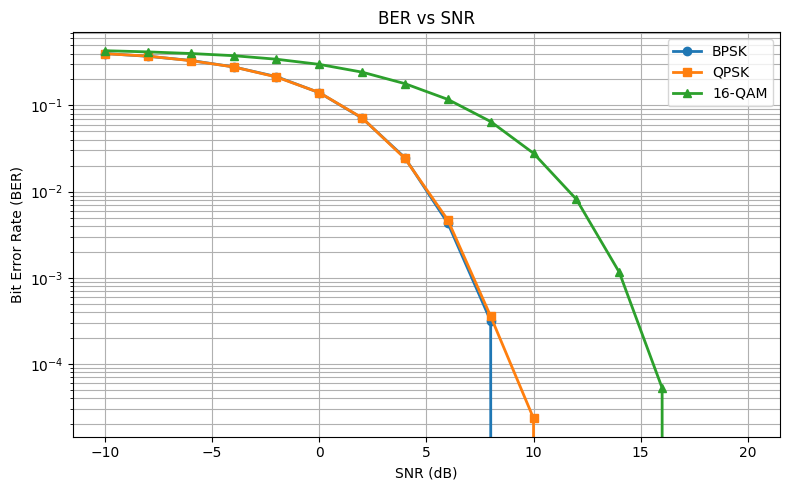

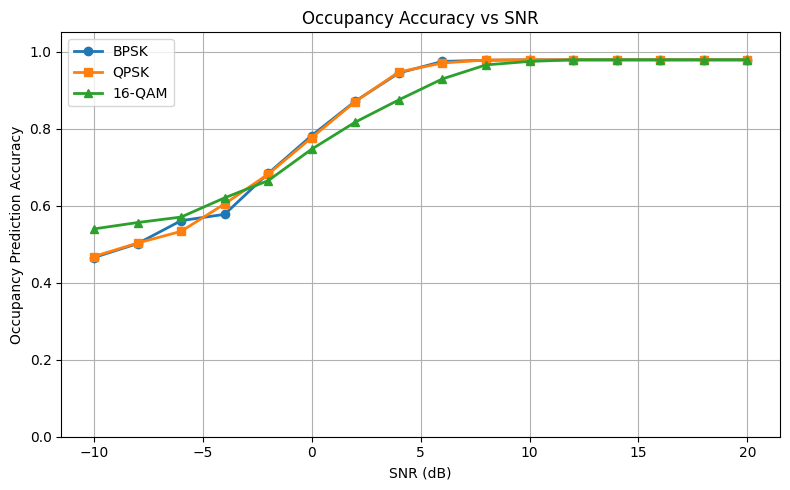

In [17]:

snr_values = np.arange(-10, 22, 2)

bpsk_ber = []
bpsk_acc = []

qpsk_ber = []
qpsk_acc = []

qam16_ber = []
qam16_acc = []

print("Running experiments...\n")

for snr in snr_values:

    ber, acc = evaluate_classical_system(
        modulation="BPSK",
        snr_db=snr
    )

    bpsk_ber.append(ber)
    bpsk_acc.append(acc)

    print(f"BPSK | SNR = {snr:>3} dB | BER = {ber:.6f} | Accuracy = {acc:.4f}")

    ber, acc = evaluate_classical_system(
        modulation="QPSK",
        snr_db=snr
    )

    qpsk_ber.append(ber)
    qpsk_acc.append(acc)

    print(f"QPSK | SNR = {snr:>3} dB | BER = {ber:.6f} | Accuracy = {acc:.4f}")

    ber, acc = evaluate_classical_system(
        modulation="16QAM",
        snr_db=snr
    )

    qam16_ber.append(ber)
    qam16_acc.append(acc)

    print(f"16-QAM | SNR = {snr:>3} dB | BER = {ber:.6f} | Accuracy = {acc:.4f}")

results = pd.DataFrame({
    "SNR (dB)": snr_values,
    "BPSK BER": bpsk_ber,
    "QPSK BER": qpsk_ber,
    "16QAM BER": qam16_ber,
    "BPSK Accuracy": bpsk_acc,
    "QPSK Accuracy": qpsk_acc,
    "16QAM Accuracy": qam16_acc
})

print("\nResults Summary")
print(results)

plt.figure(figsize=(8,5))

plt.semilogy(
    snr_values,
    bpsk_ber,
    marker='o',
    linewidth=2,
    label="BPSK"
)

plt.semilogy(
    snr_values,
    qpsk_ber,
    marker='s',
    linewidth=2,
    label="QPSK"
)

plt.semilogy(
    snr_values,
    qam16_ber,
    marker='^',
    linewidth=2,
    label="16-QAM"
)

plt.xlabel("SNR (dB)")
plt.ylabel("Bit Error Rate (BER)")
plt.title("BER vs SNR")
plt.grid(True, which='both')
plt.legend()

plt.tight_layout()
plt.show()

plt.figure(figsize=(8,5))

plt.plot(
    snr_values,
    bpsk_acc,
    marker='o',
    linewidth=2,
    label="BPSK"
)

plt.plot(
    snr_values,
    qpsk_acc,
    marker='s',
    linewidth=2,
    label="QPSK"
)

plt.plot(
    snr_values,
    qam16_acc,
    marker='^',
    linewidth=2,
    label="16-QAM"
)

plt.xlabel("SNR (dB)")
plt.ylabel("Occupancy Prediction Accuracy")
plt.title("Occupancy Accuracy vs SNR")
plt.ylim(0, 1.05)
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()


In [18]:
import matplotlib.pyplot as plt

snr_values = np.arange(-10, 22, 2)
modulation = "BPSK"

coding_results = {}

for coding in ["repetition", "hamming", "conv"]:

    ber_curve = []
    acc_curve = []

    print(f"\nRunning {coding} coding | {modulation}")

    for snr in snr_values:

        ber, acc = evaluate_classical_system(
            modulation=modulation,
            snr_db=snr,
            coding=coding
        )

        ber_curve.append(ber)
        acc_curve.append(acc)

        print(f"SNR = {snr:>3} dB | BER = {ber:.6f} | Accuracy = {acc:.4f}")

    coding_results[coding] = {"BER": ber_curve, "ACC": acc_curve}



Running repetition coding | BPSK
SNR = -10 dB | BER = 0.318205 | Accuracy = 0.5231
SNR =  -8 dB | BER = 0.275422 | Accuracy = 0.5749
SNR =  -6 dB | BER = 0.226730 | Accuracy = 0.6375
SNR =  -4 dB | BER = 0.173370 | Accuracy = 0.7092
SNR =  -2 dB | BER = 0.117167 | Accuracy = 0.7786
SNR =   0 dB | BER = 0.067478 | Accuracy = 0.8717
SNR =   2 dB | BER = 0.029538 | Accuracy = 0.9257
SNR =   4 dB | BER = 0.009557 | Accuracy = 0.9692
SNR =   6 dB | BER = 0.001530 | Accuracy = 0.9771
SNR =   8 dB | BER = 0.000141 | Accuracy = 0.9786
SNR =  10 dB | BER = 0.000000 | Accuracy = 0.9786
SNR =  12 dB | BER = 0.000000 | Accuracy = 0.9786
SNR =  14 dB | BER = 0.000000 | Accuracy = 0.9786
SNR =  16 dB | BER = 0.000000 | Accuracy = 0.9786
SNR =  18 dB | BER = 0.000000 | Accuracy = 0.9786
SNR =  20 dB | BER = 0.000000 | Accuracy = 0.9786

Running hamming coding | BPSK
SNR = -10 dB | BER = 0.399572 | Accuracy = 0.4765
SNR =  -8 dB | BER = 0.369401 | Accuracy = 0.4949
SNR =  -6 dB | BER = 0.330060 | Acc

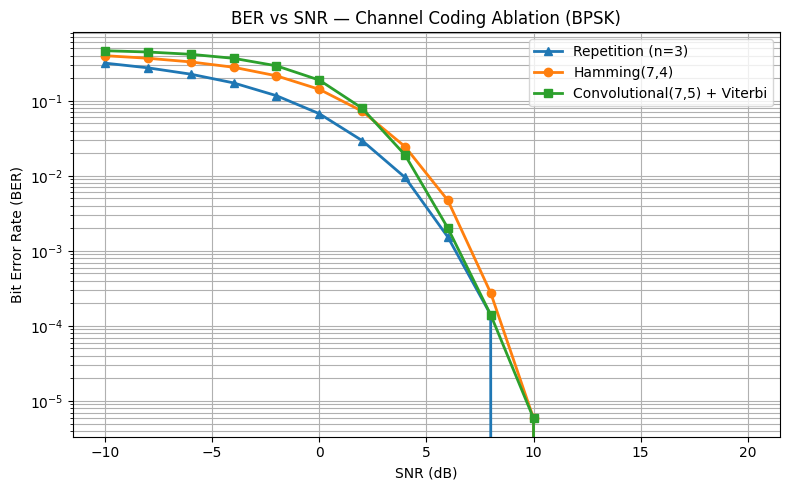

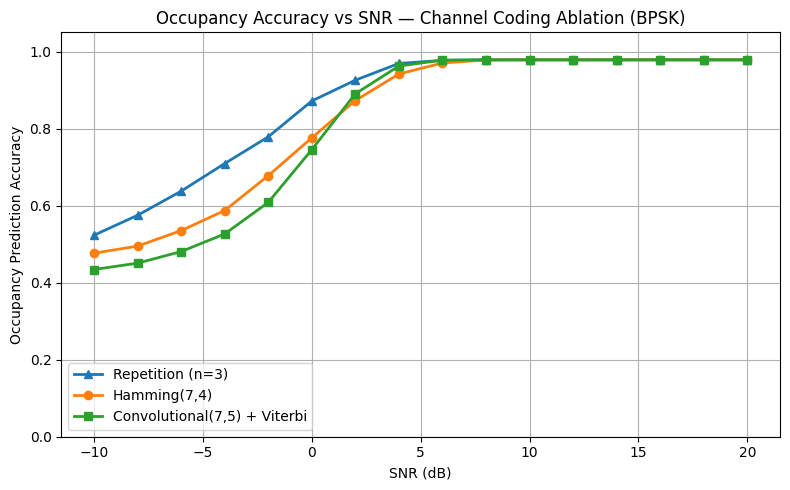

In [19]:
plt.figure(figsize=(8, 5))

plt.semilogy(snr_values, coding_results["repetition"]["BER"], marker='^', linewidth=2, label="Repetition (n=3)")
plt.semilogy(snr_values, coding_results["hamming"]["BER"], marker='o', linewidth=2, label="Hamming(7,4)")
plt.semilogy(snr_values, coding_results["conv"]["BER"], marker='s', linewidth=2, label="Convolutional(7,5) + Viterbi")

plt.xlabel("SNR (dB)")
plt.ylabel("Bit Error Rate (BER)")
plt.title(f"BER vs SNR — Channel Coding Ablation ({modulation})")
plt.grid(True, which='both')
plt.legend()
plt.tight_layout()
plt.savefig("coding_ablation_ber_vs_snr.png", dpi=300)
plt.show()

plt.figure(figsize=(8, 5))

plt.plot(snr_values, coding_results["repetition"]["ACC"], marker='^', linewidth=2, label="Repetition (n=3)")
plt.plot(snr_values, coding_results["hamming"]["ACC"], marker='o', linewidth=2, label="Hamming(7,4)")
plt.plot(snr_values, coding_results["conv"]["ACC"], marker='s', linewidth=2, label="Convolutional(7,5) + Viterbi")

plt.xlabel("SNR (dB)")
plt.ylabel("Occupancy Prediction Accuracy")
plt.title(f"Occupancy Accuracy vs SNR — Channel Coding Ablation ({modulation})")
plt.ylim(0, 1.05)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig("coding_ablation_accuracy_vs_snr.png", dpi=300)
plt.show()


In [20]:
payload_bits = len(features) * 16

hamming_coded_bits = int(np.ceil(payload_bits / 4) * 7)
conv_coded_bits = 2 * (payload_bits + 2)
repetition_coded_bits = payload_bits * 3

coding_overhead = pd.DataFrame({
    "Coding scheme": ["Repetition (n=3)", "Hamming(7,4)", "Convolutional(7,5)"],
    "Rate": [1/3, 4/7, payload_bits / conv_coded_bits],
    "Payload bits/sample": [payload_bits, payload_bits, payload_bits],
    "Coded bits/sample": [repetition_coded_bits, hamming_coded_bits, conv_coded_bits],
})

print(coding_overhead.to_string(index=False))


     Coding scheme     Rate  Payload bits/sample  Coded bits/sample
  Repetition (n=3) 0.333333                   64                192
      Hamming(7,4) 0.571429                   64                112
Convolutional(7,5) 0.484848                   64                132


## BPSK vs QPSK vs 16-QAM


In [21]:
snr_values = np.arange(-10, 22, 2)
coding_for_mod_test = "hamming"

modulation_results = {}

for modulation in ["BPSK", "QPSK", "16QAM"]:

    ber_curve = []
    acc_curve = []

    print(f"\nRunning modulation ablation | {modulation}")

    for snr in snr_values:

        ber, acc = evaluate_classical_system(
            modulation=modulation,
            snr_db=snr,
            coding=coding_for_mod_test
        )

        ber_curve.append(ber)
        acc_curve.append(acc)

        print(f"SNR = {snr:>3} dB | BER = {ber:.6f} | Accuracy = {acc:.4f}")

    modulation_results[modulation] = {"BER": ber_curve, "ACC": acc_curve}



Running modulation ablation | BPSK
SNR = -10 dB | BER = 0.399496 | Accuracy = 0.4645
SNR =  -8 dB | BER = 0.370216 | Accuracy = 0.4938
SNR =  -6 dB | BER = 0.330224 | Accuracy = 0.5400
SNR =  -4 dB | BER = 0.278225 | Accuracy = 0.6086
SNR =  -2 dB | BER = 0.215807 | Accuracy = 0.6848
SNR =   0 dB | BER = 0.139593 | Accuracy = 0.7842
SNR =   2 dB | BER = 0.072690 | Accuracy = 0.8754
SNR =   4 dB | BER = 0.023968 | Accuracy = 0.9373
SNR =   6 dB | BER = 0.004427 | Accuracy = 0.9715
SNR =   8 dB | BER = 0.000317 | Accuracy = 0.9782
SNR =  10 dB | BER = 0.000000 | Accuracy = 0.9786
SNR =  12 dB | BER = 0.000000 | Accuracy = 0.9786
SNR =  14 dB | BER = 0.000000 | Accuracy = 0.9786
SNR =  16 dB | BER = 0.000000 | Accuracy = 0.9786
SNR =  18 dB | BER = 0.000000 | Accuracy = 0.9786
SNR =  20 dB | BER = 0.000000 | Accuracy = 0.9786

Running modulation ablation | QPSK
SNR = -10 dB | BER = 0.402029 | Accuracy = 0.4638
SNR =  -8 dB | BER = 0.370233 | Accuracy = 0.5051
SNR =  -6 dB | BER = 0.32902

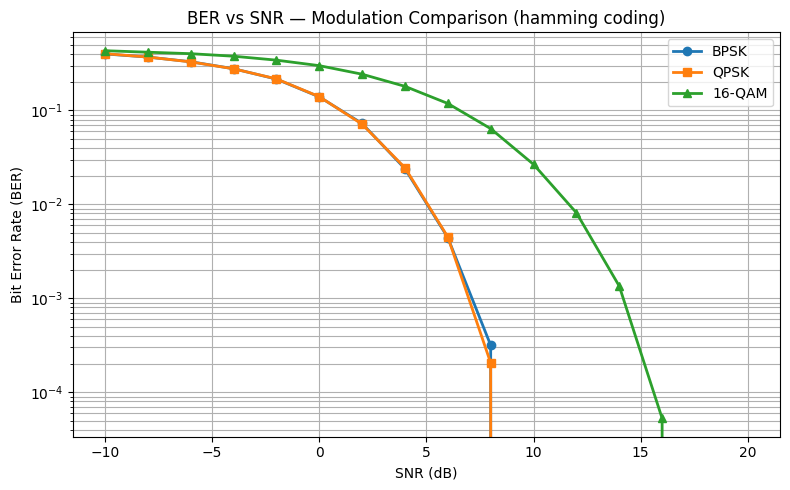

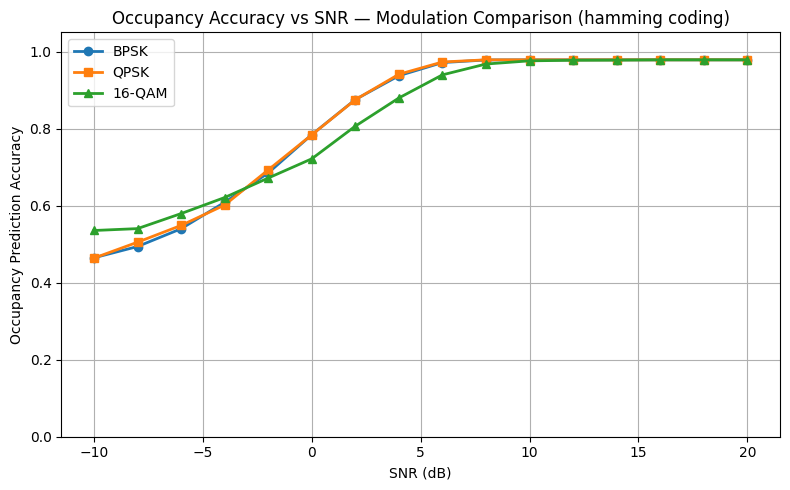

In [22]:
plt.figure(figsize=(8, 5))

plt.semilogy(snr_values, modulation_results["BPSK"]["BER"], marker='o', linewidth=2, label="BPSK")
plt.semilogy(snr_values, modulation_results["QPSK"]["BER"], marker='s', linewidth=2, label="QPSK")
plt.semilogy(snr_values, modulation_results["16QAM"]["BER"], marker='^', linewidth=2, label="16-QAM")

plt.xlabel("SNR (dB)")
plt.ylabel("Bit Error Rate (BER)")
plt.title(f"BER vs SNR — Modulation Comparison ({coding_for_mod_test} coding)")
plt.grid(True, which='both')
plt.legend()
plt.tight_layout()
plt.savefig("modulation_ablation_ber_vs_snr.png", dpi=300)
plt.show()

plt.figure(figsize=(8, 5))

plt.plot(snr_values, modulation_results["BPSK"]["ACC"], marker='o', linewidth=2, label="BPSK")
plt.plot(snr_values, modulation_results["QPSK"]["ACC"], marker='s', linewidth=2, label="QPSK")
plt.plot(snr_values, modulation_results["16QAM"]["ACC"], marker='^', linewidth=2, label="16-QAM")

plt.xlabel("SNR (dB)")
plt.ylabel("Occupancy Prediction Accuracy")
plt.title(f"Occupancy Accuracy vs SNR — Modulation Comparison ({coding_for_mod_test} coding)")
plt.ylim(0, 1.05)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig("modulation_ablation_accuracy_vs_snr.png", dpi=300)
plt.show()


In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

torch.manual_seed(0)
np.random.seed(0)

DEVICE = "cpu"

In [24]:
scaler = StandardScaler()

X_train = scaler.fit_transform(train[features].values).astype(np.float32)
X_test = scaler.transform(test[features].values).astype(np.float32)

y_train = train["Occupancy"].values.astype(np.int64)
y_test = test["Occupancy"].values.astype(np.int64)

X_train_t = torch.tensor(X_train)
y_train_t = torch.tensor(y_train)
X_test_t = torch.tensor(X_test)
y_test_t = torch.tensor(y_test)

print("Train:", X_train_t.shape, " Test:", X_test_t.shape)

Train: torch.Size([8143, 4])  Test: torch.Size([2665, 4])


In [25]:
class SemanticNet(nn.Module):
    def __init__(self, input_dim=4, semantic_dim=4, hidden=16, num_classes=2):
        super().__init__()

        self.semantic_dim = semantic_dim

        self.encoder = nn.Sequential(
            nn.Linear(input_dim, hidden),
            nn.ReLU(),
            nn.Linear(hidden, semantic_dim),
            nn.Tanh(),
        )

        self.decoder = nn.Sequential(
            nn.Linear(semantic_dim, hidden),
            nn.ReLU(),
            nn.Linear(hidden, num_classes),
        )

    def forward(self, x):
        z = self.encoder(x)
        logits = self.decoder(z)
        return logits, z


In [26]:
def train_semantic_net(semantic_dim=4, epochs=200, lr=1e-2, verbose=True):

    model = SemanticNet(input_dim=len(features), semantic_dim=semantic_dim).to(DEVICE)

    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    for epoch in range(epochs):

        model.train()
        optimizer.zero_grad()

        logits, _ = model(X_train_t)
        loss = criterion(logits, y_train_t)

        loss.backward()
        optimizer.step()

        if verbose and (epoch + 1) % 50 == 0:
            print(f"epoch {epoch+1:>4} | loss = {loss.item():.4f}")

    return model


semantic_dim = 4
model = train_semantic_net(semantic_dim=semantic_dim)

epoch   50 | loss = 0.0456
epoch  100 | loss = 0.0431
epoch  150 | loss = 0.0375
epoch  200 | loss = 0.0275


In [27]:
model.eval()

with torch.no_grad():
    logits, z_test = model(X_test_t)
    preds = logits.argmax(dim=1).numpy()

baseline_accuracy = accuracy_score(y_test, preds)

print(f"Semantic dim: {semantic_dim}")
print(f"Baseline accuracy (no channel): {baseline_accuracy:.4f}")
print(f"Semantic embedding range: [{z_test.min():.3f}, {z_test.max():.3f}]")


Semantic dim: 4
Baseline accuracy (no channel): 0.8803
Semantic embedding range: [-1.000, 1.000]


In [28]:
def quantize_semantic(value, bits=8):

    normalized = (value + 1) / 2
    normalized = np.clip(normalized, 0, 1)

    integer = int(round(normalized * (2**bits - 1)))

    return np.array(list(np.binary_repr(integer, width=bits)), dtype=int)


def dequantize_semantic(bit_array, bits=8):

    integer = int("".join(bit_array.astype(str)), 2)
    normalized = integer / (2**bits - 1)

    return normalized * 2 - 1


def semantic_vector_to_bits(z, bits=8):

    bitstream = []

    for value in z:
        bitstream.extend(quantize_semantic(value, bits))

    return np.array(bitstream)


def bits_to_semantic_vector(bitstream, semantic_dim, bits=8):

    values = []

    for i in range(semantic_dim):
        start = i * bits
        end = start + bits
        values.append(dequantize_semantic(bitstream[start:end], bits))

    return np.array(values, dtype=np.float32)


In [29]:
def evaluate_semantic_system(model, modulation="BPSK", snr_db=10, bits_per_feature=8, semantic_dim=4):

    with torch.no_grad():
        _, z_all = model(X_test_t)
    z_all = z_all.numpy()

    ber_values = []
    predictions = []

    for z in z_all:

        original_bits = semantic_vector_to_bits(z, bits_per_feature)

        recovered_bits, ber = communicate(
            original_bits,
            modulation,
            snr_db
        )

        ber_values.append(ber)

        z_hat = bits_to_semantic_vector(recovered_bits, semantic_dim, bits_per_feature)

        with torch.no_grad():
            logits_hat = model.decoder(torch.tensor(z_hat).unsqueeze(0))
            pred = logits_hat.argmax(dim=1).item()

        predictions.append(pred)

    accuracy = accuracy_score(y_test, predictions)
    average_ber = np.mean(ber_values)

    return average_ber, accuracy


ber, acc = evaluate_semantic_system(model, modulation="BPSK", snr_db=10,
                                     bits_per_feature=8, semantic_dim=semantic_dim)

print(f"BPSK @ 10 dB | semantic dim = {semantic_dim}, 8 bits/feature")
print(f"Average BER: {ber:.6f}")
print(f"Occupancy Accuracy: {acc:.4f}")

BPSK @ 10 dB | semantic dim = 4, 8 bits/feature
Average BER: 0.000000
Occupancy Accuracy: 0.8807


In [30]:
snr_values = np.arange(-10, 22, 2)
bits_per_feature = 8

semantic_results = {}

for modulation in ["BPSK", "QPSK", "16QAM"]:

    ber_curve = []
    acc_curve = []

    print(f"\nRunning semantic system | {modulation}")

    for snr in snr_values:

        ber, acc = evaluate_semantic_system(
            model,
            modulation=modulation,
            snr_db=snr,
            bits_per_feature=bits_per_feature,
            semantic_dim=semantic_dim
        )

        ber_curve.append(ber)
        acc_curve.append(acc)

        print(f"SNR = {snr:>3} dB | BER = {ber:.6f} | Accuracy = {acc:.4f}")

    semantic_results[modulation] = {"BER": ber_curve, "ACC": acc_curve}



Running semantic system | BPSK
SNR = -10 dB | BER = 0.398018 | Accuracy = 0.7013
SNR =  -8 dB | BER = 0.369289 | Accuracy = 0.7415
SNR =  -6 dB | BER = 0.331637 | Accuracy = 0.7805
SNR =  -4 dB | BER = 0.275551 | Accuracy = 0.8304
SNR =  -2 dB | BER = 0.215889 | Accuracy = 0.8432
SNR =   0 dB | BER = 0.141827 | Accuracy = 0.8717
SNR =   2 dB | BER = 0.071717 | Accuracy = 0.8792
SNR =   4 dB | BER = 0.024648 | Accuracy = 0.8803
SNR =   6 dB | BER = 0.003917 | Accuracy = 0.8799
SNR =   8 dB | BER = 0.000317 | Accuracy = 0.8807
SNR =  10 dB | BER = 0.000000 | Accuracy = 0.8807
SNR =  12 dB | BER = 0.000000 | Accuracy = 0.8807
SNR =  14 dB | BER = 0.000000 | Accuracy = 0.8807
SNR =  16 dB | BER = 0.000000 | Accuracy = 0.8807
SNR =  18 dB | BER = 0.000000 | Accuracy = 0.8807
SNR =  20 dB | BER = 0.000000 | Accuracy = 0.8807

Running semantic system | QPSK
SNR = -10 dB | BER = 0.402345 | Accuracy = 0.7062
SNR =  -8 dB | BER = 0.368773 | Accuracy = 0.7415
SNR =  -6 dB | BER = 0.329632 | Accu

In [31]:
snr_values = np.arange(-10, 22, 2)
bits_per_feature = 8

semantic_results = {}

for modulation in ["BPSK", "QPSK", "16QAM"]:

    ber_curve = []
    acc_curve = []

    print(f"\nRunning semantic system | {modulation}")

    for snr in snr_values:

        ber, acc = evaluate_semantic_system(
            model,
            modulation=modulation,
            snr_db=snr,
            bits_per_feature=bits_per_feature,
            semantic_dim=semantic_dim
        )

        ber_curve.append(ber)
        acc_curve.append(acc)

        print(f"SNR = {snr:>3} dB | BER = {ber:.6f} | Accuracy = {acc:.4f}")

    semantic_results[modulation] = {"BER": ber_curve, "ACC": acc_curve}



Running semantic system | BPSK
SNR = -10 dB | BER = 0.399660 | Accuracy = 0.6979
SNR =  -8 dB | BER = 0.369723 | Accuracy = 0.7385
SNR =  -6 dB | BER = 0.329444 | Accuracy = 0.7794
SNR =  -4 dB | BER = 0.280054 | Accuracy = 0.8045
SNR =  -2 dB | BER = 0.214071 | Accuracy = 0.8473
SNR =   0 dB | BER = 0.141745 | Accuracy = 0.8780
SNR =   2 dB | BER = 0.071353 | Accuracy = 0.8694
SNR =   4 dB | BER = 0.024437 | Accuracy = 0.8818
SNR =   6 dB | BER = 0.004491 | Accuracy = 0.8811
SNR =   8 dB | BER = 0.000152 | Accuracy = 0.8807
SNR =  10 dB | BER = 0.000000 | Accuracy = 0.8807
SNR =  12 dB | BER = 0.000000 | Accuracy = 0.8807
SNR =  14 dB | BER = 0.000000 | Accuracy = 0.8807
SNR =  16 dB | BER = 0.000000 | Accuracy = 0.8807
SNR =  18 dB | BER = 0.000000 | Accuracy = 0.8807
SNR =  20 dB | BER = 0.000000 | Accuracy = 0.8807

Running semantic system | QPSK
SNR = -10 dB | BER = 0.401513 | Accuracy = 0.6961
SNR =  -8 dB | BER = 0.370087 | Accuracy = 0.7291
SNR =  -6 dB | BER = 0.329550 | Accu

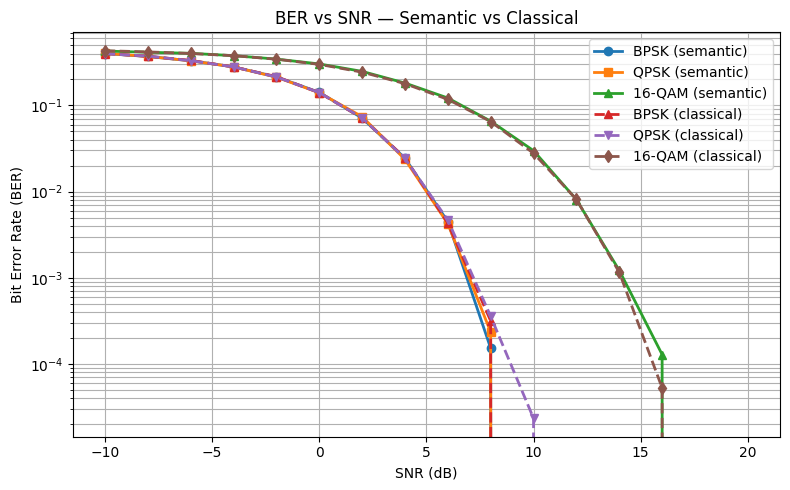

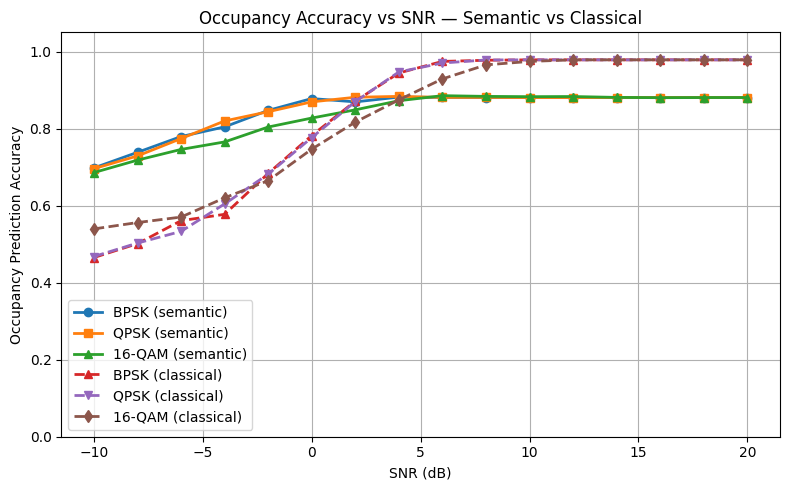

In [32]:
plt.figure(figsize=(8, 5))

plt.semilogy(snr_values, semantic_results["BPSK"]["BER"], marker='o', linewidth=2, label="BPSK (semantic)")
plt.semilogy(snr_values, semantic_results["QPSK"]["BER"], marker='s', linewidth=2, label="QPSK (semantic)")
plt.semilogy(snr_values, semantic_results["16QAM"]["BER"], marker='^', linewidth=2, label="16-QAM (semantic)")

try:
    plt.semilogy(snr_values, bpsk_ber, marker='^', linestyle='--', linewidth=2, label="BPSK (classical)")
    plt.semilogy(snr_values, qpsk_ber, marker='v', linestyle='--', linewidth=2, label="QPSK (classical)")
    plt.semilogy(snr_values, qam16_ber, marker='d', linestyle='--', linewidth=2, label="16-QAM (classical)")
except NameError:
    pass

plt.xlabel("SNR (dB)")
plt.ylabel("Bit Error Rate (BER)")
plt.title("BER vs SNR — Semantic vs Classical")
plt.grid(True, which='both')
plt.legend()
plt.tight_layout()
plt.savefig("semantic_ber_vs_snr.png", dpi=300)
plt.show()

plt.figure(figsize=(8, 5))

plt.plot(snr_values, semantic_results["BPSK"]["ACC"], marker='o', linewidth=2, label="BPSK (semantic)")
plt.plot(snr_values, semantic_results["QPSK"]["ACC"], marker='s', linewidth=2, label="QPSK (semantic)")
plt.plot(snr_values, semantic_results["16QAM"]["ACC"], marker='^', linewidth=2, label="16-QAM (semantic)")

try:
    plt.plot(snr_values, bpsk_acc, marker='^', linestyle='--', linewidth=2, label="BPSK (classical)")
    plt.plot(snr_values, qpsk_acc, marker='v', linestyle='--', linewidth=2, label="QPSK (classical)")
    plt.plot(snr_values, qam16_acc, marker='d', linestyle='--', linewidth=2, label="16-QAM (classical)")
except NameError:
    pass

plt.xlabel("SNR (dB)")
plt.ylabel("Occupancy Prediction Accuracy")
plt.title("Occupancy Accuracy vs SNR — Semantic vs Classical")
plt.ylim(0, 1.05)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig("semantic_accuracy_vs_snr.png", dpi=300)
plt.show()


In [ ]:
raw_bits_per_sample = len(features) * 16
semantic_bits_per_sample = semantic_dim * bits_per_feature

compression_ratio = raw_bits_per_sample / semantic_bits_per_sample
savings_pct = (1 - semantic_bits_per_sample / raw_bits_per_sample) * 100


bandwidth_summary = pd.DataFrame({
    "System": ["Classical", "Semantic"],
    "Payload bits/sample": [raw_bits_per_sample, semantic_bits_per_sample],
    "Coded bits/sample (Hamming 7,4)": [
        int(np.ceil(raw_bits_per_sample / 4) * 7),
        int(np.ceil(semantic_bits_per_sample / 4) * 7),
    ],
})

print(bandwidth_summary.to_string(index=False))
print(f"\nCompression ratio: {compression_ratio:.2f}x")
print(f"Bandwidth savings: {savings_pct:.1f}%")


In [ ]:
ablation_dims = [1, 2, 4, 8, 16]
ablation_snr_db = 10
ablation_bits_per_feature = 8

ablation_rows = []

for dim in ablation_dims:

    dim_model = train_semantic_net(semantic_dim=dim, epochs=200, verbose=False)

    dim_model.eval()
    with torch.no_grad():
        logits_clean, _ = dim_model(X_test_t)
        clean_acc = accuracy_score(y_test, logits_clean.argmax(dim=1).numpy())

    ber, noisy_acc = evaluate_semantic_system(
        dim_model,
        modulation="BPSK",
        snr_db=ablation_snr_db,
        bits_per_feature=ablation_bits_per_feature,
        semantic_dim=dim
    )

    bits = dim * ablation_bits_per_feature

    ablation_rows.append({
        "semantic_dim": dim,
        "bits/sample": bits,
        "clean_accuracy": clean_acc,
        f"accuracy_@{ablation_snr_db}dB_BPSK": noisy_acc,
        "BER": ber,
    })

    print(f"dim = {dim:>2} | bits = {bits:>3} | clean acc = {clean_acc:.4f} | "
          f"acc @ {ablation_snr_db}dB = {noisy_acc:.4f}")

ablation_df = pd.DataFrame(ablation_rows)
print()
print(ablation_df.to_string(index=False))

plt.figure(figsize=(8, 5))
plt.plot(ablation_df["bits/sample"], ablation_df["clean_accuracy"], marker='o', label="Clean (no channel)")
plt.plot(ablation_df["bits/sample"], ablation_df[f"accuracy_@{ablation_snr_db}dB_BPSK"], marker='s',
         label=f"BPSK @ {ablation_snr_db} dB")
plt.xlabel("Bits transmitted per sample")
plt.ylabel("Occupancy Accuracy")
plt.title("Ablation: Semantic Embedding Dimension vs Accuracy")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig("semantic_dim_ablation.png", dpi=300)
plt.show()
